# Exploratory data analysis

This notebook describes the cleaned dataset `hcv_median_imputed.csv` (608 patients) with summary tables and plots. The statistical tests are in `stats.ipynb`.

## 1. Configuration and data

Settings are defined once so every plot uses the same class order and colours. `cat_num` holds the number of each label, so it is left out of the numeric summaries.

In [1]:
# standard library and third-party imports, grouped together
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# settings used throughout: file path, class order and column lists
DATA_PATH = Path("hcv_median_imputed.csv")
SEED = 42
CLASS_ORDER = ["Healthy", "Hepatitis", "Fibrosis", "Cirrhosis"]
NUMERIC_COLS = [
    "Age", "ALB", "ALP", "ALT", "AST", "BIL",
    "CHE", "CHOL", "CREA", "GGT", "PROT",
]
# strongly right-skewed variables, drawn on a log scale in boxplots
LOG_COLS = ["ALT", "AST", "BIL", "CREA", "GGT", "ALP"]
# markers for the pairplot; the first four are log-transformed for display
PAIR_COLS = ["AST", "ALT", "GGT", "BIL", "CHE", "ALB"]
PAIR_LOG_COLS = ["AST", "ALT", "GGT", "BIL"]
N_COLS = 4

# one fixed colour per category so every figure matches
PALETTE = dict(zip(
    CLASS_ORDER, ["#4c9f70", "#e8a33d", "#d4622b", "#8c2d3f"]
))

np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")

In [2]:
# load the cleaned data and fix the category order so tables and
# plots always list Healthy first and Cirrhosis last
df = pd.read_csv(DATA_PATH)
df["Category"] = pd.Categorical(
    df["Category"], categories=CLASS_ORDER, ordered=True
)

# basic structure: number of rows and columns, column types, first rows
print("Shape:", df.shape)
print()
print(df.dtypes)
df.head()

Shape: (608, 14)

Category    category
Age          float64
Sex           object
ALB          float64
ALP          float64
ALT          float64
AST          float64
BIL          float64
CHE          float64
CHOL         float64
CREA         float64
GGT          float64
PROT         float64
cat_num        int64
dtype: object


,Category,Age,Sex,ALB,ALP,ALT,AST,BIL,CHE,CHOL,CREA,GGT,PROT,cat_num
0,Healthy,32.0,m,38.5,52.5,7.7,22.1,7.5,6.93,3.23,106.0,12.1,69.0,0
1,Healthy,32.0,m,38.5,70.3,18.0,24.7,3.9,11.17,4.80,74.0,15.6,76.5,0
2,Healthy,32.0,m,46.9,74.7,36.2,52.6,6.1,8.84,5.20,86.0,33.2,79.3,0
3,Healthy,32.0,m,43.2,52.0,30.6,22.6,18.9,7.33,4.74,80.0,33.8,75.7,0
4,Healthy,32.0,m,39.2,74.1,32.6,24.8,9.6,9.15,4.32,76.0,29.9,68.7,0


## 2. Descriptive statistics

Summary statistics for the 11 numeric variables, with skewness and kurtosis. The second table gives the median and IQR for each category.

In [3]:
# standard summary table (count, mean, spread, quartiles) for the 11
# measurements, with skewness and kurtosis added as shape measures
summary = df[NUMERIC_COLS].describe().T
summary["skew"] = df[NUMERIC_COLS].skew()
summary["kurtosis"] = df[NUMERIC_COLS].kurt()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,608.0,47.29,9.99,19.00,39.00,47.00,54.00,77.00,0.25,-0.42
ALB,608.0,41.82,5.40,20.00,39.00,42.00,45.22,82.20,0.29,6.23
ALP,608.0,67.77,24.90,11.30,52.90,66.00,79.03,416.60,4.96,63.64
ALT,608.0,27.59,21.21,0.90,16.40,23.00,32.67,258.00,4.18,30.36
AST,608.0,34.37,32.62,12.00,21.60,25.85,32.80,324.00,5.14,33.13
BIL,608.0,11.47,19.77,1.80,5.30,7.30,11.30,254.00,8.35,82.35
CHE,608.0,8.20,2.17,1.42,6.95,8.27,9.59,16.41,-0.16,1.40
CHOL,608.0,5.38,1.11,1.43,4.63,5.30,6.06,9.67,0.40,0.79
CREA,608.0,81.51,49.72,8.00,68.00,77.00,88.00,1079.10,15.36,283.91
GGT,608.0,38.24,51.95,4.50,15.70,23.25,39.20,650.90,6.11,52.30


In [4]:
# median and IQR (75th minus 25th percentile) of each variable within
# each category. These ignore extreme values, unlike the mean
grouped = df.groupby("Category", observed=True)[NUMERIC_COLS]
median = grouped.median()
iqr = grouped.quantile(0.75) - grouped.quantile(0.25)

# stack the two tables and arrange rows as variable then statistic
by_class = pd.concat({"median": median, "IQR": iqr}, axis=1)
by_class = by_class.T.swaplevel().sort_index(level=0, sort_remaining=False)
by_class.reindex(NUMERIC_COLS, level=0).round(2)

Category     Healthy  Hepatitis  Fibrosis  Cirrhosis
Age  median    47.00      37.00     51.00      56.00
     IQR       14.00      15.50      9.00      13.00
ALB  median    42.20      43.50     41.00      33.00
     IQR        6.20       4.50      6.00       6.75
ALP  median    66.70      36.95     45.20      67.80
     IQR       24.30      24.77     26.70      43.95
ALT  median    23.10      18.30     34.00       5.65
     IQR       15.10      28.80    103.80      21.60
AST  median    24.80      47.20     70.00      92.90
     IQR        8.70      44.22     63.00      60.45
BIL  median     6.90      13.00     13.00      34.00
     IQR        5.10       8.50      5.00      42.50
CHE  median     8.35       9.51      8.59       3.42
     IQR        2.52       2.74      2.17       3.92
CHOL median     5.38       5.06      4.64       3.92
     IQR        1.43       1.68      0.80       1.26
CREA median    78.00      72.25     71.40      68.50
     IQR       20.00      19.65     13.70      41.45
GGT  median    21.40      45.55     72.20      96.35
     IQR       16.90      56.75     42.30      91.60
PROT median    72.20      73.65     76.10      70.25
     IQR        5.80       6.03      8.60      10.48

## 3. Categorical variables

Counts of each category, and sex within each category.

           count  percent
Category                 
Healthy      533     87.7
Hepatitis     24      3.9
Fibrosis      21      3.5
Cirrhosis     30      4.9


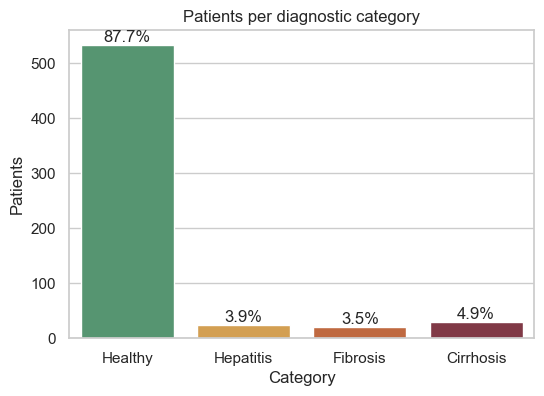

In [5]:
# number and share of patients in each diagnostic category
counts = df["Category"].value_counts().reindex(CLASS_ORDER)
class_table = pd.DataFrame({
    "count": counts,
    "percent": (counts / len(df) * 100).round(1),
})
print(class_table)

# bar chart of the counts, with the percentage written above each bar
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(
    x=counts.index, y=counts.values, hue=counts.index,
    palette=PALETTE, legend=False, ax=ax,
)
for patch, pct in zip(ax.patches, class_table["percent"]):
    x_centre = patch.get_x() + patch.get_width() / 2
    ax.annotate(
        f"{pct}%", (x_centre, patch.get_height()),
        ha="center", va="bottom",
    )
ax.set_title("Patients per diagnostic category")
ax.set_xlabel("Category")
ax.set_ylabel("Patients")
plt.show()

In [6]:
# overall number and share of male and female patients
sex_counts = df["Sex"].value_counts()
print(pd.DataFrame({
    "count": sex_counts,
    "percent": (sex_counts / len(df) * 100).round(1),
}))

# Sex within each category, as counts and as a percentage of the row
sex_by_class = pd.crosstab(df["Category"], df["Sex"])
sex_by_class_pct = pd.crosstab(
    df["Category"], df["Sex"], normalize="index"
) * 100
print()
print("Counts")
print(sex_by_class)
print()
print("Row percentages")
print(sex_by_class_pct.round(1))

     count  percent
Sex                
m      371     61.0
f      237     39.0

Counts
Sex          f    m
Category           
Healthy    215  318
Hepatitis    4   20
Fibrosis     8   13
Cirrhosis   10   20

Row percentages
Sex           f     m
Category             
Healthy    40.3  59.7
Hepatitis  16.7  83.3
Fibrosis   38.1  61.9
Cirrhosis  33.3  66.7


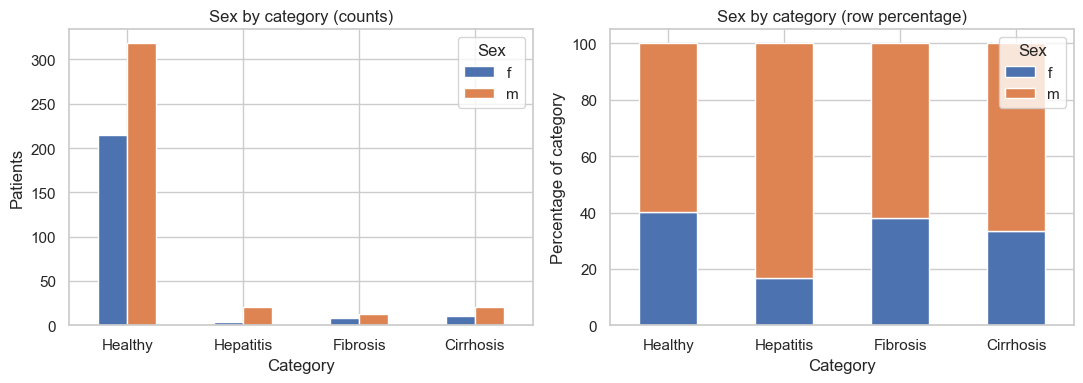

In [7]:
# left: side-by-side counts. Right: stacked percentages, which make
# the male share comparable between categories of different size
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sex_by_class.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Sex by category (counts)")
axes[0].set_ylabel("Patients")
sex_by_class_pct.plot(kind="bar", stacked=True, ax=axes[1], rot=0)
axes[1].set_title("Sex by category (row percentage)")
axes[1].set_ylabel("Percentage of category")
for ax in axes:
    ax.set_xlabel("Category")
plt.tight_layout()
plt.show()

## 4. Distributions

Histograms show the shape of each variable over all patients.

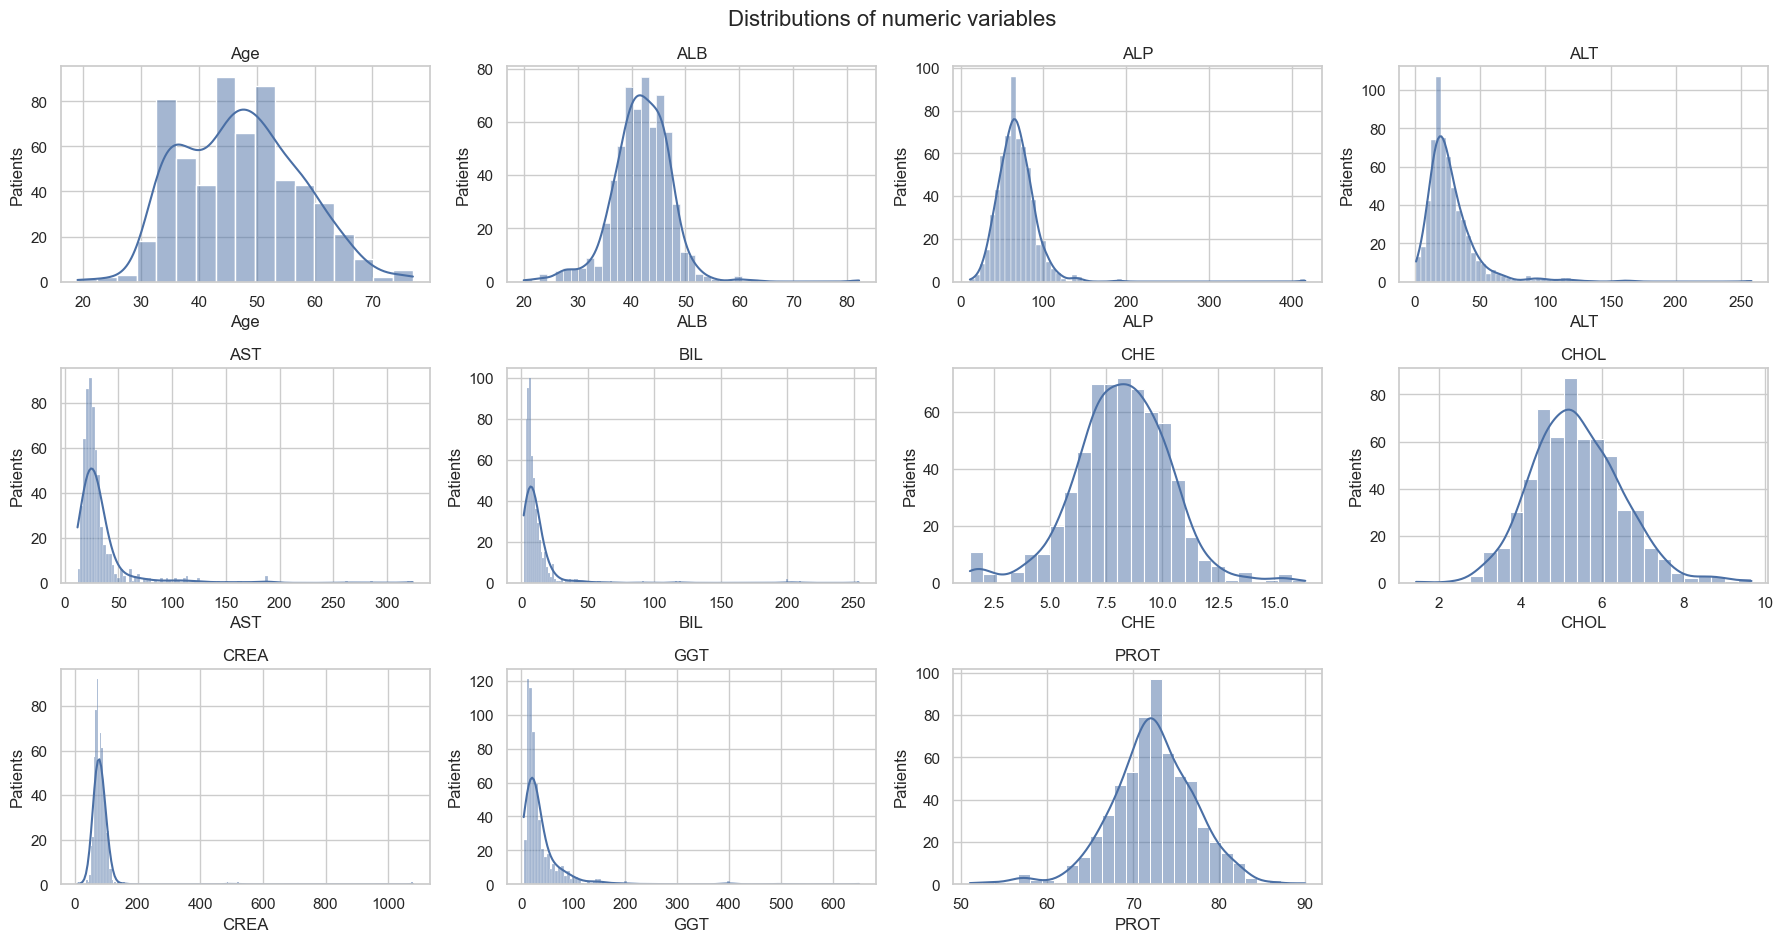

In [8]:
# distribution plots (4 per row)
n_rows = int(np.ceil(len(NUMERIC_COLS) / N_COLS))
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(18, 3.2 * n_rows))
axes = axes.flatten()

# loop through each variable
for i, col in enumerate(NUMERIC_COLS):
    sns.histplot(df[col], bins="fd", kde=True, color="#4a6fa5", ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel("Patients")

# remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle("Distributions of numeric variables", fontsize=16)
plt.tight_layout()
plt.show()

## 5. Relationships with the target

Boxplots compare each variable across the four categories. ALT, AST, BIL, CREA, GGT and ALP are drawn on a log scale because they are strongly right-skewed. The three disease classes have only 21 to 30 patients each.

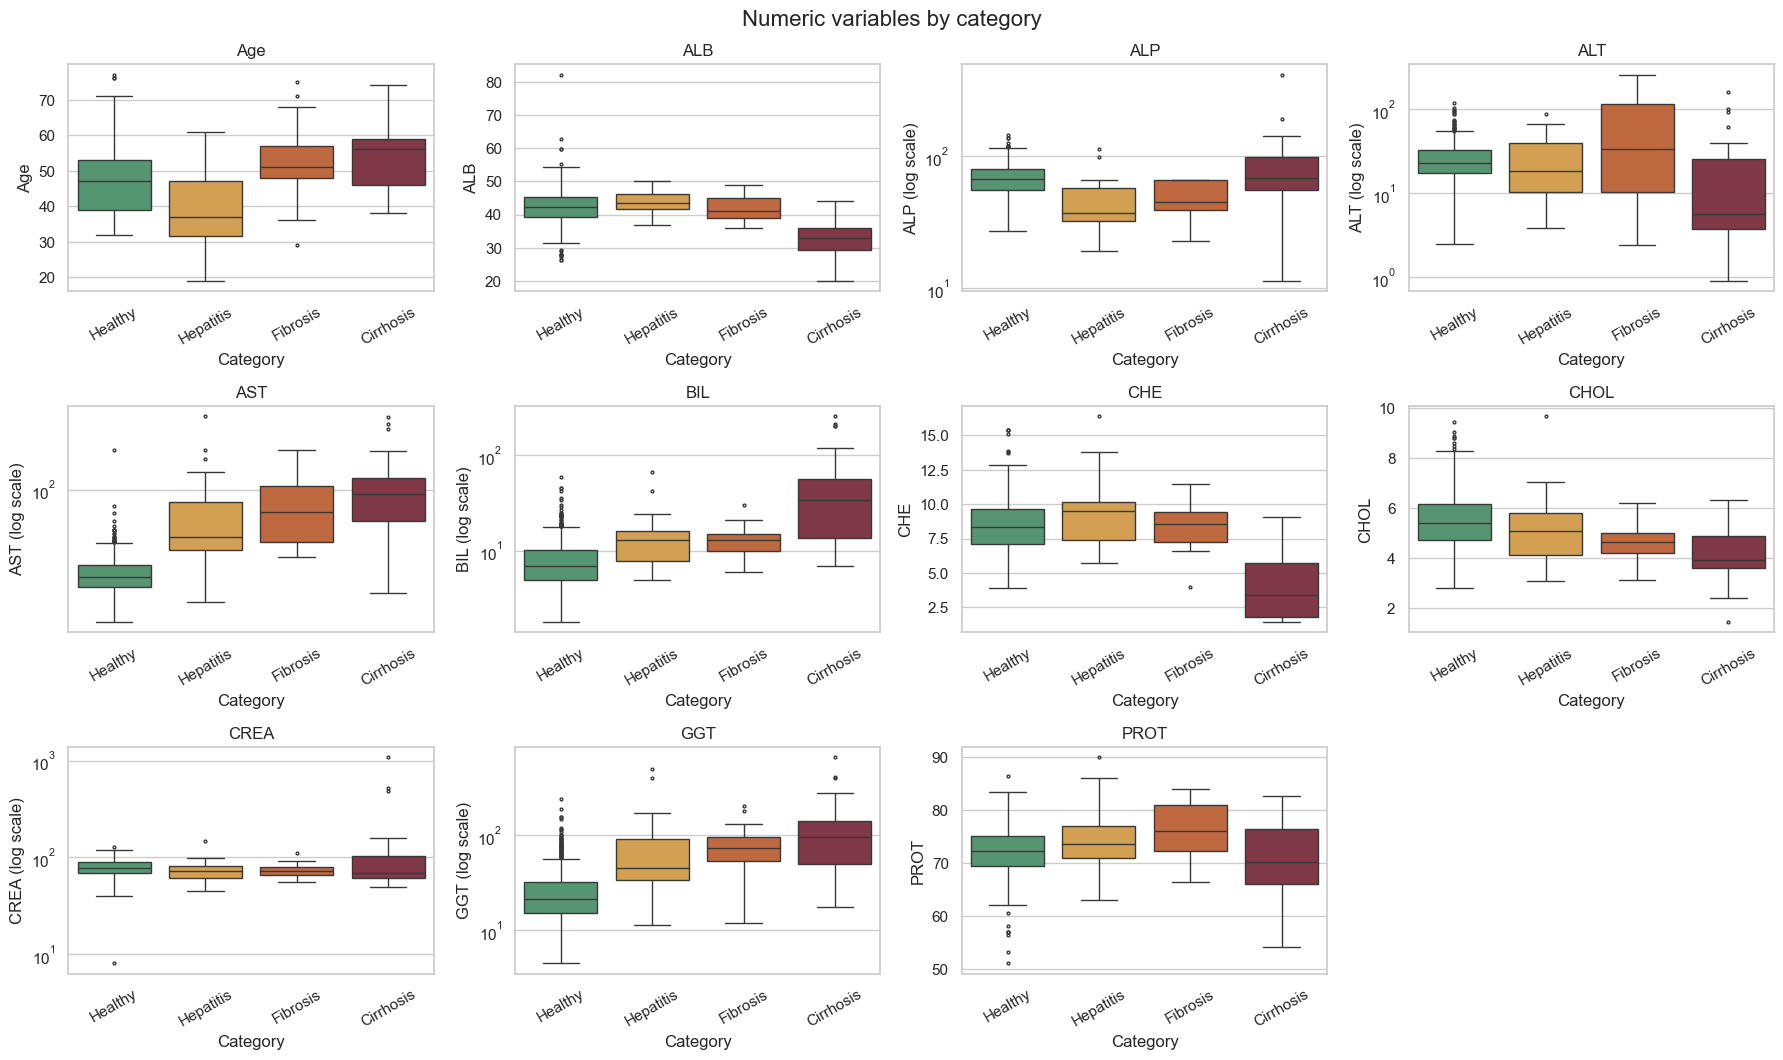

In [9]:
# boxplots of every variable split by category (4 per row)
fig, axes = plt.subplots(n_rows, N_COLS, figsize=(18, 3.6 * n_rows))
axes = axes.flatten()

# loop through each variable
for i, col in enumerate(NUMERIC_COLS):

    # one box per category, in class order and fixed colours
    sns.boxplot(
        data=df, x="Category", y=col, hue="Category",
        order=CLASS_ORDER, hue_order=CLASS_ORDER,
        palette=PALETTE, legend=False, fliersize=2, ax=axes[i],
    )

    # skewed variables get a log axis so small boxes stay visible
    if col in LOG_COLS:
        axes[i].set_yscale("log")
        axes[i].set_ylabel(f"{col} (log scale)")

    # formatting each plot
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=30)

# remove empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# formatting full figure
plt.suptitle("Numeric variables by category", fontsize=16)
plt.tight_layout()
plt.show()

## 6. Relationships between variables

Pearson correlation measures linear relationships and is affected by outliers. Spearman correlation uses ranks, so it is less affected. Both are shown.

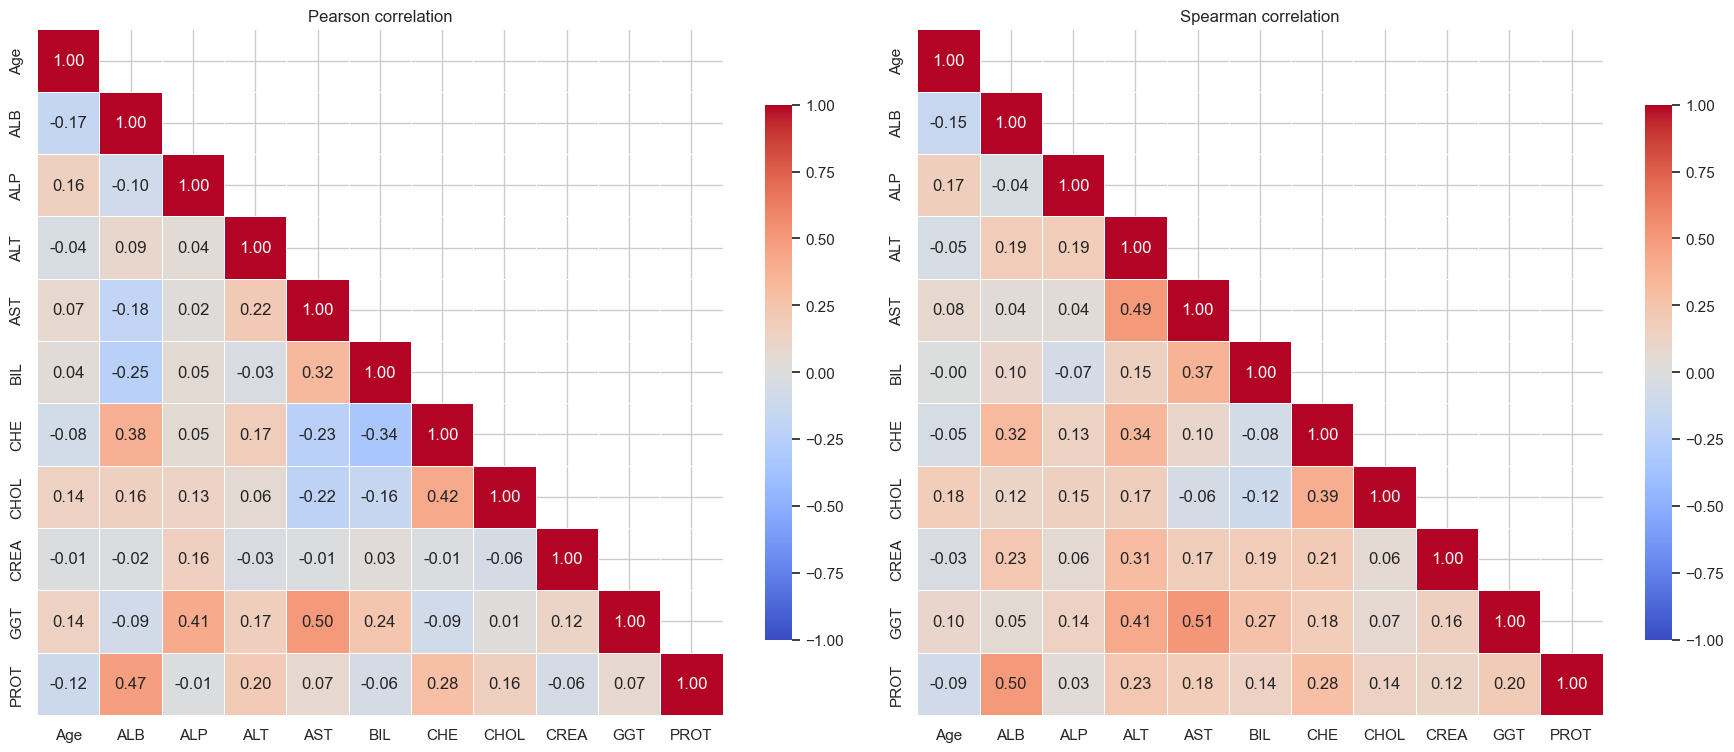

In [10]:
# Pearson (linear) and Spearman (rank-based) correlation matrices
pearson = df[NUMERIC_COLS].corr(method="pearson")
spearman = df[NUMERIC_COLS].corr(method="spearman")

# hide the upper triangle: the matrix is symmetric, so it repeats
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)

# draw both heatmaps side by side with the same colour scale
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, corr, name in zip(axes, [pearson, spearman],
                          ["Pearson", "Spearman"]):
    sns.heatmap(
        corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
        vmin=-1, vmax=1, square=True, linewidths=0.5,
        cbar_kws={"shrink": 0.7}, ax=ax,
    )
    ax.set_title(f"{name} correlation")
plt.tight_layout()
plt.show()

In [11]:
# list the five strongest pairs (ignoring the diagonal) for each method
for name, corr in [("Pearson", pearson), ("Spearman", spearman)]:
    # keep each pair once by taking only the lower triangle
    lower = corr.where(np.tril(np.ones(corr.shape, dtype=bool), k=-1))
    pairs = lower.stack()
    order = pairs.abs().sort_values(ascending=False).index
    print(f"Strongest {name} pairs")
    print(pairs.reindex(order)[:5].round(2))
    print()

Strongest Pearson pairs
GGT   AST    0.50
PROT  ALB    0.47
CHOL  CHE    0.42
GGT   ALP    0.41
CHE   ALB    0.38
dtype: float64

Strongest Spearman pairs
GGT   AST    0.51
PROT  ALB    0.50
AST   ALT    0.49
GGT   ALT    0.41
CHOL  CHE    0.39
dtype: float64



The pairplot shows six liver markers by category. AST, ALT, GGT and BIL are shown as log10 values so that a few extreme patients do not squash the rest. This is for display only.

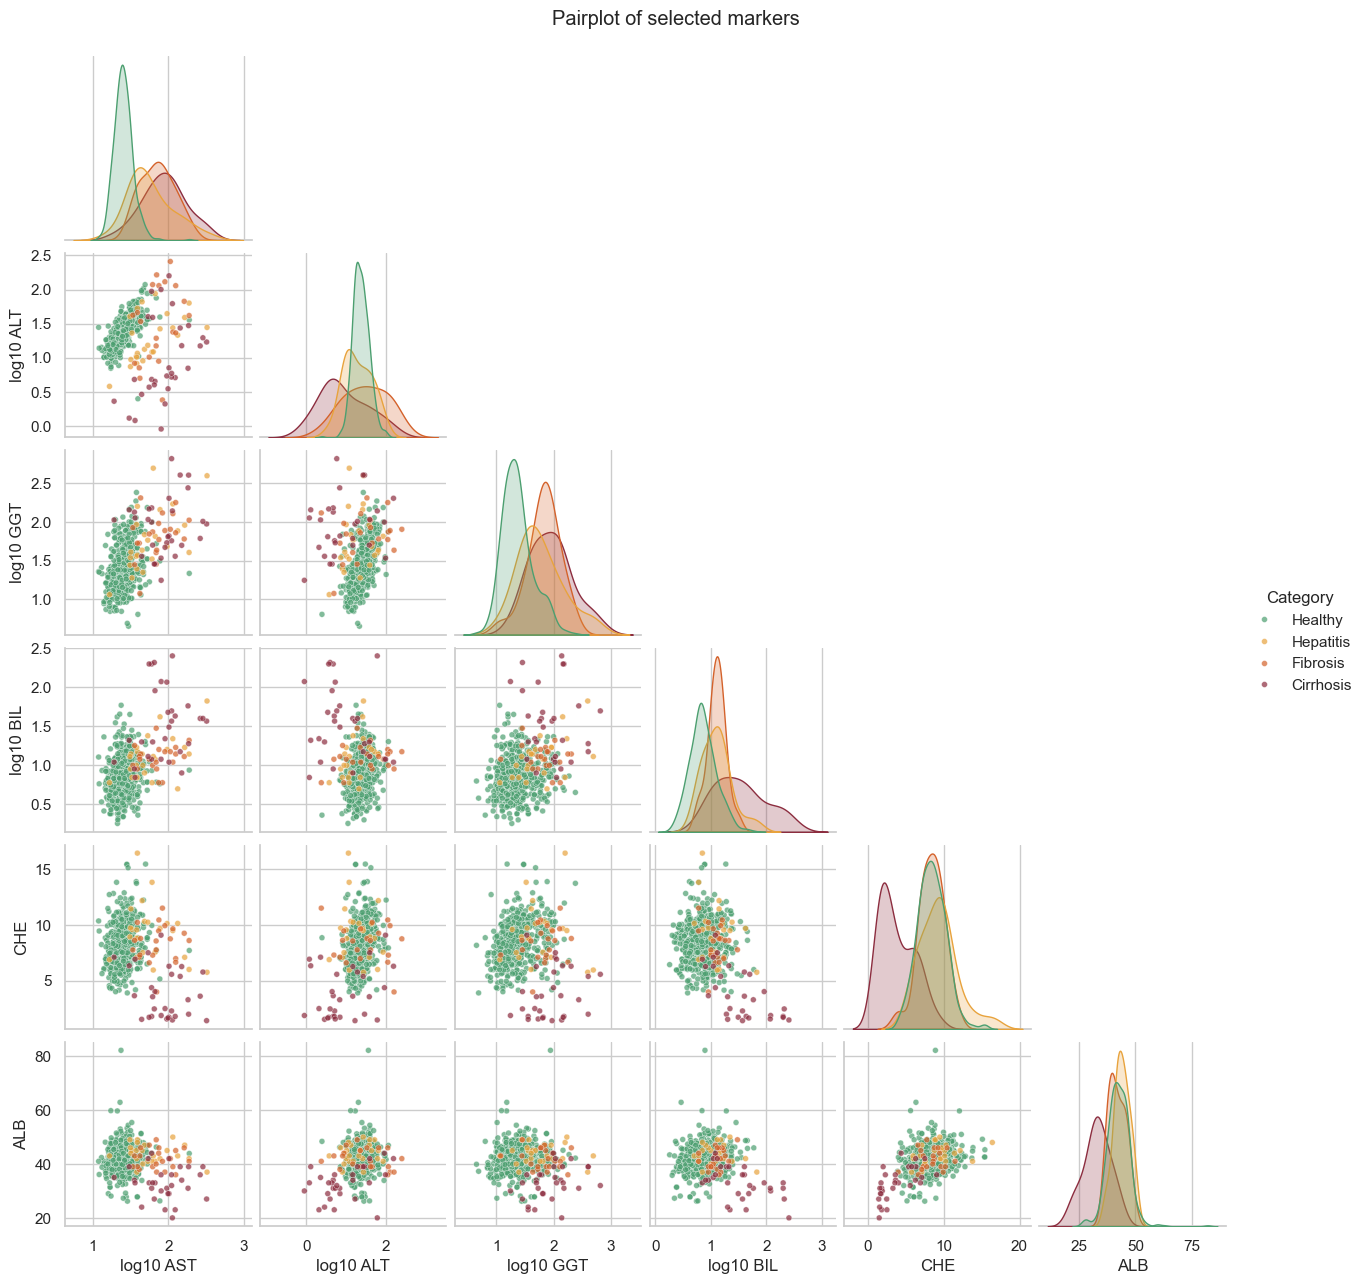

In [12]:
# copy the data and replace the skewed markers by their log10 values,
# renaming the columns so the axis labels say they are logged
pair_data = df[PAIR_COLS + ["Category"]].copy()
for column in PAIR_LOG_COLS:
    pair_data[f"log10 {column}"] = np.log10(pair_data[column])
    pair_data = pair_data.drop(columns=column)

# keep the original marker order, using the renamed columns
pair_vars = [
    f"log10 {c}" if c in PAIR_LOG_COLS else c for c in PAIR_COLS
]

# scatter plots by category, with density curves on the diagonal
pair_grid = sns.pairplot(
    pair_data, vars=pair_vars, hue="Category", hue_order=CLASS_ORDER,
    palette=PALETTE, corner=True, diag_kind="kde",
    plot_kws={"s": 18, "alpha": 0.7}, diag_kws={"common_norm": False},
    height=2.1,
)
pair_grid.figure.suptitle("Pairplot of selected markers", y=1.02)
plt.show()

## 7. Summary of observations

- **Class imbalance.** 533 of 608 patients are healthy (87.7%). Hepatitis, Fibrosis and Cirrhosis have 24, 21 and 30 patients.
- **Sex.** 371 patients are male (61.0%). The male share is 59.7% in Healthy, 83.3% in Hepatitis, 61.9% in Fibrosis and 66.7% in Cirrhosis.
- **Skewness.** CREA (15.36), BIL (8.35), GGT (6.11), AST (5.14), ALP (4.96) and ALT (4.18) are strongly right-skewed. Age, ALB, CHE, CHOL and PROT are close to symmetric.
- **Differences by class.** Median AST rises from 24.80 in Healthy to 47.20, 70.00 and 92.90 in Hepatitis, Fibrosis and Cirrhosis. Median GGT rises from 21.40 to 45.55, 72.20 and 96.35. Median BIL is 6.90 in Healthy and 34.00 in Cirrhosis. Median CHE and ALB are lowest in Cirrhosis (3.42 and 33.00, against 8.35 and 42.20 in Healthy). Median CREA changes little between classes.
- **Correlations.** The correlations are modest. The strongest Pearson pairs are GGT-AST (0.50), PROT-ALB (0.47) and CHOL-CHE (0.42). Spearman gives similar values.